# Lab 4: Production Outlier Pipeline — Diagnostic Lab

**ECON 5200: Causal Machine Learning & Applied Analytics**

This lab uses a **diagnosis-first** format. You will:
1. Find and fix 3 bugs in a broken outlier detection pipeline
2. Read and run a finished `OutlierDetector` class, saved as a `.py` module
3. Compare three outlier detection methods on California Housing and write a method selection memo

**Time estimate:** about 60 minutes (Part 0: 15 min, Part 1: 30 min, Part 2: 15 min; Part 3 is take-home)

**Prerequisites:** Chapter 4 reading, including [5200-DEPTH] sections on robust statistics and breakdown points

**AI in the manual parts:** you may ask Colab to *explain* an error or a line of code (click **Explain error**, or select a line and ask Gemini to explain it). Do not ask it to write or fix code, and turn off AI code completion while you work on those parts. AI-assisted coding is allowed only where this lab says so.

## Setup

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import IsolationForest

df = fetch_california_housing(as_frame=True).frame

print(f"{df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

20,640 rows, 9 columns


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


<!-- 5200-onramp -->
## Part 0: Build It First (GUIDED — 15 min)

Part 2 gives you `outlier_detector.py`, a module built around an
`OutlierDetector` **class**. To read it you need three tools this part covers:
dictionaries, the scikit-learn **estimator** pattern, and `class` — what
`__init__` and `self` actually do.

### Step 0a: dictionaries, and the estimator pattern

A **dictionary** is a lookup table. A list answers "what is in position 2?";
a dictionary answers "what is the value for `k`?" In this course dictionaries
mostly hold settings and results.

An **estimator** is how every model in this course works, in three steps:

1. **Build** it with settings: `model = IsolationForest(contamination=0.05)`
2. **Fit** it to data: `model.fit(X)`. The model now *remembers* what it learned.
3. **Ask** it: `model.predict(X)`

`np.mean(x)` is a function: you hand it data, it answers, it forgets. An
estimator is an object that keeps what it learned. Values it learned end in
an underscore, like `model.n_features_in_`.

In [45]:
# GUIDED — run as-is
# Step 0a: dictionaries, and the estimator pattern

settings = {"method": "tukey", "k": 1.5, "contamination": 0.05}
print(settings["method"], settings["k"])
for name, value in settings.items():
    print(" ", name, value)

X = df[["MedInc", "HouseAge", "AveRooms"]]

model = IsolationForest(contamination=0.05, random_state=42)   # 1. build
model.fit(X)                                                    # 2. fit
flags = model.predict(X)                                        # 3. ask: -1 = outlier

n_flagged = (flags == -1).sum()
print(f"\nIsolation Forest flagged {n_flagged:,} of {len(flags):,} rows "
      f"({n_flagged / len(flags):.1%})")
# n_features_in_ ends in _ because the model learned it from the data
print(f"The fitted model remembers it saw {model.n_features_in_} features")

tukey 1.5
  method tukey
  k 1.5
  contamination 0.05

Isolation Forest flagged 1,032 of 20,640 rows (5.0%)
The fitted model remembers it saw 3 features


### Step 0b: writing your own class

A **class** is a blueprint for an object that holds settings and learned
values. Three words cover it:

| Word | What it is |
|---|---|
| `__init__` | runs when you write `TukeyDetector(...)`; stores the settings |
| `self` | the object itself; how a method reaches what `__init__` stored |
| attribute | a value stored on the object, such as `self.k` |

scikit-learn's convention, which Part 2 follows: settings have plain names
(`self.k`), values learned from data end in an underscore (`self.lower_`), and
`.fit()` returns `self`, so `.fit(x).detect(x)` works in one line. Inside the
class, use `self.k`, never a literal `1.5`, or the setting does nothing.

One more piece: `raise` stops the program with an error message, and
`try` / `except` catches that error so the notebook keeps going. The last lines
of the cell show `detect()` refusing to run before `fit()`.

In [46]:
# GUIDED — run as-is
# Step 0b: writing your own class

class TukeyDetector:
    """Flag values outside the Tukey fences. A small version of Part 2's class."""

    def __init__(self, k=1.5):
        self.k = k            # a setting
        self.lower_ = None    # learned by fit()
        self.upper_ = None

    def fit(self, series):
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        self.lower_ = q1 - self.k * iqr
        self.upper_ = q3 + self.k * iqr
        return self

    def detect(self, series):
        if self.lower_ is None:
            raise RuntimeError("call .fit() before .detect()")
        return (series < self.lower_) | (series > self.upper_)


prices = df["MedHouseVal"]
print(f"prices run from {prices.min():.2f} to {prices.max():.2f}\n")

for k in [1.5, 3.0]:
    det = TukeyDetector(k=k).fit(prices)
    n_flagged = det.detect(prices).sum()
    print(f"k={k}  fences [{det.lower_:.3f}, {det.upper_:.3f}]  flagged {n_flagged:,}")

# detect() before fit() raises the error written above
try:
    TukeyDetector().detect(prices)
except RuntimeError as e:
    print(f"\nTukeyDetector().detect(...) -> RuntimeError: {e}")

prices run from 0.15 to 5.00

k=1.5  fences [-0.981, 4.824]  flagged 1,071
k=3.0  fences [-3.158, 7.001]  flagged 0

TukeyDetector().detect(...) -> RuntimeError: call .fit() before .detect()


### Now diagnose

You have now used somebody else's estimator and written your own. Part 2's
`OutlierDetector` has the same shape with three changes: it offers three
methods instead of one, it merges `fit` and `detect` into one `fit_detect()`,
and it checks its settings when you build it. It also labels its arguments
with type hints: `data: pd.Series` means "this should be a pandas Series".
Python does not enforce the label; it is there for the reader.

Notice what the `k=3.0` run just told you, because Part 1 turns on it: prices
stop at 5.00, but the upper fence sits at 7.00, so it flagged nothing at all.
A detector that returns zero is not evidence of clean data. It is a result that
needs explaining, and "the fence is beyond the largest value in the data" is
usually the explanation.

---

## Part 1: Find and Fix the Bugs (DIAGNOSTIC — 30 min)

You’ve been given an outlier detection pipeline that has **3 bugs**. Each bug represents a common mistake that even experienced data scientists make. Your job: find each bug, explain why it’s wrong, and fix it.

The pipeline implements three methods:
- **Modified Z-score** (robust, using median and MAD)
- **Tukey Fences** (IQR-based, the box plot rule)
- **Isolation Forest** (tree-based anomaly detection)

**Hint:** The bugs are related to:
- Robustness (which center/spread measure is used)
- A classic off-by-memory constant
- A hyperparameter set to an absurd value

In [47]:
# BROKEN CODE — find and fix the 3 bugs

def modified_zscore_broken(series, threshold=3.5):
    """Modified Z-score: a robust score built from the median and the MAD."""
    center = series.mean()
    spread = series.std()
    z_scores = (series - center) / spread
    return np.abs(z_scores) > threshold


def tukey_fence_broken(series, k=1.0):
    """Tukey fences: flag values below Q1 - k*IQR or above Q3 + k*IQR."""
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - k * iqr) | (series > q3 + k * iqr)


def isolation_forest_broken(df_numeric, contamination=0.5, random_state=42):
    """Isolation Forest: flag the rows that take the fewest splits to isolate."""
    iso = IsolationForest(contamination=contamination, random_state=random_state)
    preds = iso.fit_predict(df_numeric)
    return pd.Series(preds == -1, index=df_numeric.index)

In [48]:
# RUN THE BROKEN PIPELINE — look at what it reports

test_col = df["MedInc"]                  # median income, right-skewed
numeric_cols = df.columns               # all nine columns are numbers

print(f"MedInc: mean={test_col.mean():.2f}, median={test_col.median():.2f}, "
      f"std={test_col.std():.2f}")
print(f"MedInc skewness: {test_col.skew():.2f}")
print()

# Each result is True/False per row. .sum() counts the Trues;
# .mean() is the share that is True.
z_outliers   = modified_zscore_broken(test_col)
t_outliers   = tukey_fence_broken(test_col)
iso_outliers = isolation_forest_broken(df[numeric_cols])

print(f"Modified Z-score outliers: {z_outliers.sum()} ({z_outliers.mean():.1%})")
print(f"Tukey Fence outliers:      {t_outliers.sum()} ({t_outliers.mean():.1%})")
print(f"Isolation Forest outliers: {iso_outliers.sum()} ({iso_outliers.mean():.1%})")

MedInc: mean=3.87, median=3.53, std=1.90
MedInc skewness: 1.65

Modified Z-score outliers: 215 (1.0%)
Tukey Fence outliers:      1252 (6.1%)
Isolation Forest outliers: 10320 (50.0%)


### Diagnose Each Bug

For each bug, explain:
1. **What’s wrong** (1 sentence)
2. **Why it matters** (what does the error do to the output?)
3. **The fix** (show corrected code)

---

**Bug 1** — name it yourself:

*What’s wrong:* The wrong calculation for the Z-score, which doesn't match the docstring. It's simply the rudimentary version whilst we state we wish to use the MAD variant.

*Why it matters:* The two formulas produce different solutions and the correct one described in the function description conducts a more rigorous calculation.

*Your fix:* (in the cell below)

---

**Bug 2** — name it yourself:

*What’s wrong:* The default value of k was set to the value of `1.0`.

*Why it matters:* This cuts off too much data as it determines far more of the data to be outliers than it should, despite that not being the case by convention.

*Your fix:* (in the cell below)

---

**Bug 3** — name it yourself:

*What’s wrong:* Default value of `contamination` was set at the value of `0.5`.

*Why it matters:* In this case that means the isolation forest runs until 50% of the data is removed through the method as it is the following calculation for how much data should be cut off: `contamination * 100 = percentage cut off`. This meant that half of the data was cut off as an outlier.

*Your fix:* (in the cell below)

In [49]:
# YOUR FIXES
# These start as copies of the broken code, so the checks below
# fail until you fix them. Edit each function until it does what its
# docstring says.

def modified_zscore_fixed(series, threshold=3.5):
    """Modified Z-score: 0.6745 * (x - median) / MAD, flagged when |z| > threshold."""
    center = series.median() #first fix
    mad = np.median(np.abs(series - center)) #No MAD formula
    z_scores = 0.6745 * (series - center) / (mad)
    return np.abs(z_scores) > threshold


def tukey_fence_fixed(series, k=1.5):  #k was set to equal 1.0
    """Tukey fences: flag values below Q1 - k*IQR or above Q3 + k*IQR."""
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - k * iqr) | (series > q3 + k * iqr)


def isolation_forest_fixed(df_numeric, contamination=0.05, random_state=42): #50% of data removed
    """Isolation Forest: flag the rows that take the fewest splits to isolate."""
    iso = IsolationForest(contamination=contamination, random_state=random_state)
    preds = iso.fit_predict(df_numeric)
    return pd.Series(preds == -1, index=df_numeric.index)

In [50]:
# RUN THE FIXED PIPELINE

z_outliers_fixed   = modified_zscore_fixed(test_col)
t_outliers_fixed   = tukey_fence_fixed(test_col)
iso_outliers_fixed = isolation_forest_fixed(df[numeric_cols])

print(f"Modified Z-score outliers: {z_outliers_fixed.sum()} ({z_outliers_fixed.mean():.1%})")
print(f"Tukey Fence outliers:      {t_outliers_fixed.sum()} ({t_outliers_fixed.mean():.1%})")
print(f"Isolation Forest outliers: {iso_outliers_fixed.sum()} ({iso_outliers_fixed.mean():.1%})")

Modified Z-score outliers: 400 (1.9%)
Tukey Fence outliers:      681 (3.3%)
Isolation Forest outliers: 1032 (5.0%)


### Verification Checkpoint 1

After fixing all 3 bugs, your results on `MedInc` should approximately match:

| Method | Outliers Flagged | Percentage |
|--------|-----------------|------------|
| Modified Z-score (threshold=3.5) | ~350–450 | ~1.7–2.2% |
| Tukey Fence (k=1.5) | ~600–750 | ~3.0–3.6% |
| Isolation Forest (contamination=0.05) | ~1032 | ~5.0% |

(Measured on this data: **400**, **681** and **1032** respectively.)

Key sanity checks:
- Modified Z-score should flag the **fewest** (most conservative with threshold=3.5)
- Tukey should flag **more than Z-score** because MedInc is right-skewed
- Isolation Forest should flag **close to 5%** because contamination=0.05
- No method should flag more than ~15% of the data

If any method flags >20%, the corresponding bug is not yet fixed.

In [51]:
# VERIFICATION — run after your fixes

checks = {
    "Z-score flags 350-450 rows":     350 <= z_outliers_fixed.sum() <= 450,
    "Tukey flags 600-750 rows":       600 <= t_outliers_fixed.sum() <= 750,
    "Isolation Forest flags ~5%":     abs(iso_outliers_fixed.mean() - 0.05) < 0.02,
    "Z-score flags fewer than Tukey": z_outliers_fixed.sum() < t_outliers_fixed.sum(),
}

for name, passed in checks.items():
    if passed:
        print("  PASS ", name)
    else:
        print("  FAIL ", name)

print()
if all(checks.values()):
    print("All checks passed. Your fixes are correct.")
else:
    print("Some checks failed. Review your fixes above.")

  PASS  Z-score flags 350-450 rows
  PASS  Tukey flags 600-750 rows
  PASS  Isolation Forest flags ~5%
  PASS  Z-score flags fewer than Tukey

All checks passed. Your fixes are correct.


---

## Part 2: The `OutlierDetector` Module (EXTENSION — 15 min)

Here is the finished class. It puts your three fixed functions behind one
interface and saves them as an importable `.py` module, which is part of what
you submit. Read it against your fixed functions: find where each one lives,
where the settings are checked, and what `summary()` returns. Then run it and
the test cell below.

In [52]:
%%writefile outlier_detector.py
"""OutlierDetector: one interface to three outlier-detection methods."""

import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest


class OutlierDetector:
    """Detect outliers with one of three methods.

    method         'tukey', 'zscore' or 'isolation_forest'
    k              Tukey fence multiplier            (tukey only)
    threshold      modified Z-score cutoff           (zscore only)
    contamination  share of rows to flag             (isolation_forest only)

    After fit_detect(), the results are in mask_, n_outliers_ and pct_outliers_.
    """

    VALID_METHODS = ("tukey", "zscore", "isolation_forest")

    def __init__(self, method: str = "tukey", threshold: float = 3.5,
                 k: float = 1.5, contamination: float = 0.05,
                 random_state: int = 42):
        if method not in self.VALID_METHODS:
            raise ValueError(f"method must be one of {self.VALID_METHODS}, got '{method}'")
        if threshold <= 0:
            raise ValueError(f"threshold must be positive, got {threshold}")
        if k <= 0:
            raise ValueError(f"k must be positive, got {k}")
        if not 0 < contamination < 0.5:
            raise ValueError(f"contamination must be in (0, 0.5), got {contamination}")

        self.method = method
        self.threshold = threshold
        self.k = k
        self.contamination = contamination
        self.random_state = random_state

        self.mask_ = None
        self.n_outliers_ = None
        self.pct_outliers_ = None

    def fit_detect(self, data: pd.Series | pd.DataFrame) -> pd.Series:
        """Return a boolean mask, True for outliers.

        'tukey' and 'zscore' take one column (a Series);
        'isolation_forest' takes a DataFrame of numeric columns.
        """
        if self.method != "isolation_forest" and not isinstance(data, pd.Series):
            raise TypeError(f"'{self.method}' works on one column: pass a pd.Series")

        if self.method == "zscore":
            mask = self._zscore(data)
        elif self.method == "tukey":
            mask = self._tukey(data)
        else:
            mask = self._isolation_forest(data)

        self.mask_ = mask
        # int() and float() turn numpy numbers into plain Python ones,
        # so summary() prints cleanly
        self.n_outliers_ = int(mask.sum())
        self.pct_outliers_ = float(mask.mean())
        return mask

    def summary(self) -> dict:
        """The method, how many rows it flagged, and the parameter it used."""
        if self.mask_ is None:
            raise RuntimeError("Call fit_detect() first.")

        if self.method == "zscore":
            params = {"threshold": self.threshold}
        elif self.method == "tukey":
            params = {"k": self.k}
        else:
            params = {"contamination": self.contamination}

        return {
            "method": self.method,
            "n_outliers": self.n_outliers_,
            "pct_outliers": round(self.pct_outliers_, 4),
            "params": params,
        }

    def _zscore(self, series: pd.Series) -> pd.Series:
        median = series.median()
        mad = np.median(np.abs(series - median))
        if mad == 0:    # over half the values are identical; avoid dividing by zero
            return pd.Series(False, index=series.index)
        modified_z = 0.6745 * (series - median) / mad
        return np.abs(modified_z) > self.threshold

    def _tukey(self, series: pd.Series) -> pd.Series:
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        return (series < q1 - self.k * iqr) | (series > q3 + self.k * iqr)

    def _isolation_forest(self, data: pd.Series | pd.DataFrame) -> pd.Series:
        if isinstance(data, pd.Series):
            data = data.to_frame()
        iso = IsolationForest(contamination=self.contamination,
                              random_state=self.random_state)
        preds = iso.fit_predict(data)
        return pd.Series(preds == -1, index=data.index)

Overwriting outlier_detector.py


In [53]:
# TEST — check the module works

import importlib
import outlier_detector
importlib.reload(outlier_detector)      # picks up your edits when you re-run %%writefile
from outlier_detector import OutlierDetector

print("=== Test 1: Tukey method ===")
det_tukey = OutlierDetector(method="tukey", k=1.5)
det_tukey.fit_detect(df["MedInc"])
print(det_tukey.summary())
print()

print("=== Test 2: Modified Z-score ===")
det_z = OutlierDetector(method="zscore", threshold=3.5)
det_z.fit_detect(df["MedInc"])
print(det_z.summary())
print()

print("=== Test 3: Isolation Forest ===")
det_iso = OutlierDetector(method="isolation_forest", contamination=0.05)
det_iso.fit_detect(df[numeric_cols])
print(det_iso.summary())
print()

print("=== Same rows as your Part 1 fixes? ===")
print("  Tukey:  ", (det_tukey.mask_ == t_outliers_fixed).all())
print("  Z-score:", (det_z.mask_ == z_outliers_fixed).all())
print()

print("=== Test 4: Parameter validation ===")
try:
    OutlierDetector(method="invalid")
    print("  NOT caught: method='invalid' was accepted")
except ValueError as e:
    print(f"  Caught expected error: {e}")

try:
    OutlierDetector(method="isolation_forest", contamination=0.8)
    print("  NOT caught: contamination=0.8 was accepted")
except ValueError as e:
    print(f"  Caught expected error: {e}")

=== Test 1: Tukey method ===
{'method': 'tukey', 'n_outliers': 681, 'pct_outliers': 0.033, 'params': {'k': 1.5}}

=== Test 2: Modified Z-score ===
{'method': 'zscore', 'n_outliers': 400, 'pct_outliers': 0.0194, 'params': {'threshold': 3.5}}

=== Test 3: Isolation Forest ===
{'method': 'isolation_forest', 'n_outliers': 1032, 'pct_outliers': 0.05, 'params': {'contamination': 0.05}}

=== Same rows as your Part 1 fixes? ===
  Tukey:   True
  Z-score: True

=== Test 4: Parameter validation ===
  Caught expected error: method must be one of ('tukey', 'zscore', 'isolation_forest'), got 'invalid'
  Caught expected error: contamination must be in (0, 0.5), got 0.8


### Verification Checkpoint 2

Your module tests should confirm:
- All three methods run without error on California Housing data
- `summary()` returns a dict with keys `method`, `n_outliers`, `pct_outliers`, `params`
- Invalid method name raises `ValueError`
- `contamination=0.8` raises `ValueError` (must be < 0.5)
- Tukey and Z-score results match your fixed functions from Part 1

---

## Part 3: Method Comparison — Venn Diagram (CHALLENGE — take-home)

All three methods claim to detect outliers, but they flag **different observations**. The two cells below run all three on California Housing and draw the overlap as a Venn diagram. Your work is what follows them: two interpretation questions and a 200-word memo recommending which method to use.

In [54]:
# GIVEN — install the Venn diagram package
!pip install matplotlib-venn -q

In [55]:
# GUIDED — run as-is: run all three methods and compare

mask_zscore = OutlierDetector(method="zscore", threshold=3.5).fit_detect(df["MedInc"])
mask_tukey  = OutlierDetector(method="tukey", k=1.5).fit_detect(df["MedInc"])
mask_iso    = OutlierDetector(method="isolation_forest",
                              contamination=0.05).fit_detect(df[numeric_cols])

# row labels each method flagged, as sets, so & gives the overlap
set_z = set(df.index[mask_zscore])
set_t = set(df.index[mask_tukey])
set_i = set(df.index[mask_iso])

all_three = set_z & set_t & set_i
z_and_t = set_z & set_t
z_and_i = set_z & set_i
t_and_i = set_t & set_i

print(f"Z-score flags:   {len(set_z)}")
print(f"Tukey flags:     {len(set_t)}")
print(f"IsoForest flags: {len(set_i)}")
print()
print(f"Flagged by all 3:           {len(all_three)}")
print(f"Flagged by Z-score & Tukey: {len(z_and_t)}")
print(f"Flagged by Z-score & IF:    {len(z_and_i)}")
print(f"Flagged by Tukey & IF:      {len(t_and_i)}")

Z-score flags:   400
Tukey flags:     681
IsoForest flags: 1032

Flagged by all 3:           322
Flagged by Z-score & Tukey: 400
Flagged by Z-score & IF:    322
Flagged by Tukey & IF:      377


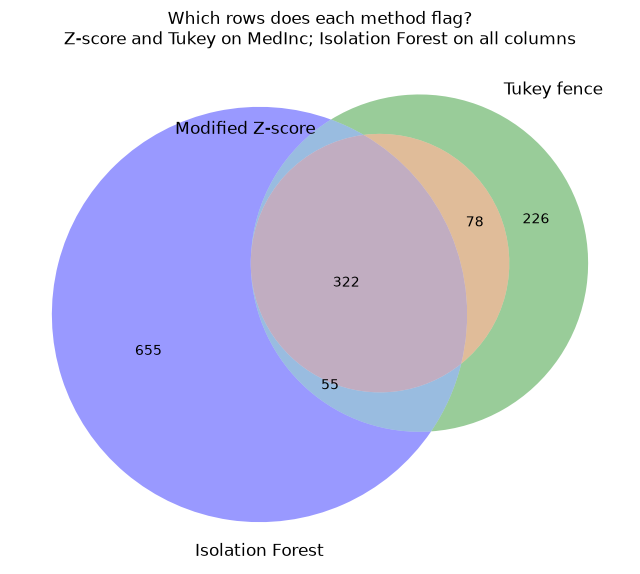

Total unique observations flagged: 1336
Flagged by >= 2 methods: 455 (34.1%)
Flagged by all 3: 322


In [56]:
# GUIDED — run as-is: draw the Venn diagram
from matplotlib_venn import venn3

fig, ax = plt.subplots(figsize=(8, 8))
venn3([set_z, set_t, set_i],
      set_labels=("Modified Z-score", "Tukey fence", "Isolation Forest"), ax=ax)
ax.set_title("Which rows does each method flag?\n"
             "Z-score and Tukey on MedInc; Isolation Forest on all columns")
plt.show()

any_flagged = set_z | set_t | set_i
at_least_two = z_and_t | z_and_i | t_and_i

print(f"Total unique observations flagged: {len(any_flagged)}")
print(f"Flagged by >= 2 methods: {len(at_least_two)} "
      f"({len(at_least_two) / len(any_flagged):.1%})")
print(f"Flagged by all 3: {len(all_three)}")

### Interpretation: Why Do Methods Disagree?

**Q1:** The Venn diagram likely shows limited overlap between Isolation Forest and the other two methods. Why? (Hint: think about what input each method receives.)

*Your answer here:* In the code in making of this diagram the code for the Z-score and Tukey receives `df['MedInc']` which is only one column, whilst the isolation forest actually gets passed in `df[numeric_cols]` which is nine columns. So it flags rows that are unusual in the joint distribution whilst the other two calculations have not considered these types of outliers and closer match each other. Second of all it is also a much bigger circle due to the reason that it doesn't have a threshold to calculate to, what this simply does is already be given a number of how many outliers there are and then picks the values furthest from most (simplifying) up to that desired prior passed in value which in this case is `0.05 = 5%`.

**Q2:** Modified Z-score and Tukey are both univariate and robust, yet they flag different observations. Under what distribution shape would they agree most? Disagree most?

*Your answer here:* Due to one built in assumption these two methods agree the most on a normal distribution. Tukey at the typical `k = 1.5` sits at around 2.7 standard deviations whilst the modified Z-score at `threshold = 3.5` sits at 3.5 standard deviations, since the built in `0.6745` constant rescales the MAD so that on a normal distribution it matches an ordinary standard deviation. Due to this the results are the most similar on a symmetric data set with two light tails. The biggest difference would exist at very high skew and a heavy tail as well, since Tukey's fences are asymmetric and follow the tail more than the modified Z-score, which is centred on the median. MedInc has skew 1.65, which is why you see 681 against 400.

### Method Selection Memo (200 words)

You are a data scientist advising a policy team that uses California Housing data to allocate affordable-housing funding. They ask: "Which outlier detection method should we use to clean this data before modeling?"

Write a 200-word memo recommending a method (or combination). Address:
1. Which method and why
2. What you would lose by choosing a different method
3. Whether "outlier" always means "should be removed"

---

*Your memo here:*
Firstly, I would wish to see what the skew of the data actually is and also if there is a reasoning behind it that is obvious without deep research. For housing the tail will most likely be to the right, and a heavy tail at that as well. This is because the lowest price housing is common and around the same price whilst luxurious mansions can spread by large amounts on their prices into very large multiples of the average house price. I would most likely use the Tukey method, although losing precision in this scenario, I believe that its ability to be asymmetric brings value to this policy making as the incredibly expensive houses do not help us in creating policies for affordable-housing and more so skew our data in ways that will not help make a better decision.

We would lose the ability to let the sample itself decide how many outliers there are, this would be the case with the isolation forest where we would lose observations due to the fact that we will have to guess what a valid percentage of outliers is in this case, and the adjusted Z-score method would not give us the asymmetric cut-offs that a heavily tailed sample needs.

Many times the outliers are outliers for a reason for example the GDP of countries yes we may remove outliers by this case but lose a huge part of the narrative for analysis of size, maybe for how long the country has been an outlier, what their economy looks like and more that made those values be what they are. Yes countries are outliers but they also tell a narrative.

---
## AI-Assisted Expansion: Outlier Method Explorer

**AI policy: foundations first, expansion second.** You have fixed the pipeline, built `OutlierDetector` and compared the three methods by hand. From here on, AI may write code for you (the Co-Pilot Rule).

### Your Expansion Task
Build ONE interactive explorer, inside this notebook (ipywidgets + plotly), that lets the user:
1. Pick a California Housing column
2. Tune each method's parameter — modified Z-score `threshold`, Tukey `k`, Isolation Forest `contamination`
3. See how many observations each method flags and how many all three agree on
4. Click through the flagged rows to decide whether they are errors or real extremes

Import your `OutlierDetector`; do not rewrite it.

### P.R.I.M.E. Prompt
Copy and paste this into Claude or ChatGPT:

In [57]:
# AI EXPANSION — copy the prompt below into Claude, then paste
# its code at the bottom of this cell. Run it and check it.

# [Prep] Act as an expert Python data scientist specializing
# in robust statistics and anomaly detection.
#
# [Request] I just completed a diagnosis-first lab where I fixed
# three bugs in an outlier pipeline and built an OutlierDetector
# class with method in {'zscore', 'tukey', 'isolation_forest'},
# threshold, k, contamination, a fit_detect() method and a
# summary() method, then compared the three methods on
# California Housing. Build ONE interactive explorer in VS Code:
#   1. a column dropdown over the housing DataFrame df
#   2. sliders for threshold (modified Z), k (Tukey) and
#      contamination (Isolation Forest)
#   3. counts flagged by each method and by all three
#   4. a table of the flagged rows for the selected method
#
# [Iterate] Use ipywidgets, plotly and pandas. Import
# OutlierDetector from outlier_detector and reuse df. No
# Streamlit and no new .py file.
#
# [Mechanism Check] Add inline comments explaining:
#   - why the modified Z-score uses the median and MAD with the
#     0.6745 constant
#   - why Tukey fences are asymmetric on skewed data
#   - why Isolation Forest can flag rows the univariate methods
#     never will
#
# [Evaluate] Explain whether "flagged" should ever mean
# "removed" for a policy team allocating housing funds.

# PASTE AI-GENERATED CODE BELOW:

# ============================================================
# Interactive outlier explorer: California Housing (ONE cell)
# Reuses `df` from earlier cells and OutlierDetector from
# outlier_detector.py. Uses go.FigureWidget + ipywidgets so it
# renders in VS Code Jupyter. No Streamlit, no new module.
# ============================================================
from functools import lru_cache

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display

from outlier_detector import OutlierDetector

NUM_COLS = df.select_dtypes("number").columns.tolist()
METHODS = ["zscore", "tukey", "isolation_forest"]
MAX_TABLE_ROWS = 200


def to_mask(result, index=df.index):
    """Coerce fit_detect() output to a boolean Series aligned to df.index.
    Handles a boolean mask, sklearn-style -1/1 labels, or the flagged
    rows themselves. Adjust if your fit_detect returns something else."""
    if isinstance(result, pd.DataFrame):
        bool_cols = result.select_dtypes(bool).columns
        if len(bool_cols):
            result = result[bool_cols[0]]
        else:  # returned only the flagged rows
            return pd.Series(index.isin(result.index), index=index)
    if isinstance(result, pd.Series):
        if result.dtype == bool:
            return result.reindex(index, fill_value=False)
        if len(result) < len(index):  # returned only the flagged values
            return pd.Series(index.isin(result.index), index=index)
        result = result.values
    arr = np.asarray(result)
    if arr.dtype != bool and set(np.unique(arr)) <= {-1, 1}:
        arr = arr == -1
    return pd.Series(arr.astype(bool), index=index)


# --- Mechanism 1: modified Z-score ---------------------------
# M_i = 0.6745 * (x_i - median) / MAD. Median and MAD have a 50%
# breakdown point, so the extreme values being hunted cannot drag the
# center or inflate the scale. With mean/SD, a cluster of outliers
# inflates SD and hides itself (masking). 0.6745 is the 75th percentile
# of N(0,1): for normal data MAD = 0.6745*sigma, so MAD/0.6745 estimates
# sigma and M_i sits on the same scale as an ordinary z-score. Hence the
# conventional 3.5 cutoff (Iglewicz & Hoaglin).
# (If your fit_detect expects a DataFrame, pass df[[col]] instead.)
def zscore_mask(col, thr):
    return to_mask(OutlierDetector(method="zscore", threshold=thr).fit_detect(df[col]))


# --- Mechanism 2: Tukey fences --------------------------------
# Fences sit at Q1 - k*IQR and Q3 + k*IQR: symmetric around the box,
# not around the data. On right-skewed columns (Population, AveOccup,
# MedInc) the median sits closer to Q1, the upper tail runs far past
# Q3 + k*IQR, and the lower fence often falls below the minimum (even
# below 0), so almost every flag lands on the high side.
# Caveat: MedHouseVal is top-coded at 5.0 ($500k); that pile-up gets
# flagged even though it is a censoring artifact, not an anomaly.
def tukey_mask(col, k):
    return to_mask(OutlierDetector(method="tukey", k=k).fit_detect(df[col]))


# --- Mechanism 3: Isolation Forest ----------------------------
# Fit on ALL numeric features jointly. Random splits isolate rows in
# sparse regions of the joint space, so a row can be flagged for an
# unusual COMBINATION (e.g. many rooms but low income) even when every
# single column is ordinary. Z-score and Tukey see one marginal at a
# time and can never flag such a row (see "IF only" count).
# Note: contamination fixes the flagged share in advance; IF flags
# about that share whether or not real anomalies exist.
# Cached because it does not depend on the selected column.
@lru_cache(maxsize=32)
def iforest_mask(cont):
    det = OutlierDetector(method="isolation_forest", contamination=cont)
    return to_mask(det.fit_detect(df[NUM_COLS]))


# --- Widgets --------------------------------------------------
style = {"description_width": "110px"}
col_dd = widgets.Dropdown(options=NUM_COLS,
                          value="MedInc" if "MedInc" in NUM_COLS else NUM_COLS[0],
                          description="Column", style=style)
thr_sl = widgets.FloatSlider(value=3.5, min=2.0, max=6.0, step=0.1,
                             description="Mod-Z threshold", style=style,
                             continuous_update=False)
k_sl = widgets.FloatSlider(value=1.5, min=0.5, max=3.0, step=0.1,
                           description="Tukey k", style=style,
                           continuous_update=False)
cont_sl = widgets.FloatSlider(value=0.02, min=0.005, max=0.10, step=0.005,
                              readout_format=".3f", description="IF contamination",
                              style=style, continuous_update=False)
table_tb = widgets.ToggleButtons(options=METHODS, value="zscore",
                                 description="Table rows:", style=style)
counts_html = widgets.HTML()
table_html = widgets.HTML()

fig = go.FigureWidget(layout=dict(
    barmode="overlay", height=380, yaxis_type="log", yaxis_title="rows (log)",
    margin=dict(t=60, l=50, r=20, b=40), legend=dict(orientation="h", y=1.15)))
fig.add_histogram(name="all rows", opacity=0.3, marker_color="grey")
for m, c in zip(METHODS, ["#1f77b4", "#ff7f0e", "#d62728"]):
    fig.add_histogram(name=f"flagged: {m}", opacity=0.75, marker_color=c)

state = {"masks": None}


def counts_table(masks):
    all3 = masks["zscore"] & masks["tukey"] & masks["isolation_forest"]
    if_only = masks["isolation_forest"] & ~(masks["zscore"] | masks["tukey"])
    rows = list(masks.items()) + [("all three", all3),
                                  ("IF only (multivariate)", if_only)]
    body = "".join(
        f"<tr><td>{name}</td><td style='text-align:right;padding:0 10px'>{m.sum():,}</td>"
        f"<td style='text-align:right'>{m.mean():.2%}</td></tr>"
        for name, m in rows)
    return ("<table><tr><th align='left'>method</th><th>flagged</th><th>share</th></tr>"
            f"{body}</table>")


def render_table(*_):
    m, col = table_tb.value, col_dd.value
    sel = state["masks"][m]
    rows = df.loc[sel].sort_values(col, ascending=False)
    table_html.value = (
        f"<b>{m}</b>: {sel.sum():,} flagged rows, sorted by {col} "
        f"(showing up to {MAX_TABLE_ROWS})"
        "<div style='max-height:320px;overflow:auto'>"
        f"{rows.head(MAX_TABLE_ROWS).to_html(float_format='%.3f')}</div>")


def refresh(*_):
    col = col_dd.value
    state["masks"] = {
        "zscore": zscore_mask(col, thr_sl.value),
        "tukey": tukey_mask(col, k_sl.value),
        "isolation_forest": iforest_mask(round(cont_sl.value, 3)),
    }
    counts_html.value = counts_table(state["masks"])
    x = df[col]
    lo, hi = float(x.min()), float(x.max())
    bins = dict(start=lo, end=hi, size=(hi - lo) / 80 or 1.0)
    with fig.batch_update():
        fig.data[0].update(x=x.values, xbins=bins)
        for tr, m in zip(fig.data[1:], METHODS):
            tr.update(x=x[state["masks"][m]].values, xbins=bins)
        fig.layout.title.text = f"{col}: all rows vs flagged rows"
        fig.layout.xaxis.title.text = col
    render_table()


for w in (col_dd, thr_sl, k_sl, cont_sl):
    w.observe(refresh, names="value")
table_tb.observe(render_table, names="value")

refresh()
display(widgets.VBox([
    widgets.HBox([widgets.VBox([col_dd, thr_sl, k_sl, cont_sl]), counts_html]),
    fig, table_tb, table_html]))

# ============================================================
# [Evaluate] Should "flagged" ever mean "removed" for a policy
# team allocating housing funds?
# Almost never automatically. A flag is a prompt to investigate:
# - The tails are often the policy target. Extreme AveOccup
#   (overcrowding), very low MedInc, or odd income/value combinations
#   can mark the block groups most in need; dropping them biases
#   allocation away from exactly those places.
# - Some flags are artifacts that need correct handling, not deletion:
#   the $500k MedHouseVal top-code (treat as censored) and ratio
#   features (AveRooms, AveOccup) inflated by tiny household counts or
#   group quarters (re-derive from raw counts).
# - The methods disagree (compare each count to "all three"), and IF's
#   count is set by the contamination knob, so "removed" rows would
#   reflect a tuning choice, not a fact about the data.
# Remove only verified errors (impossible or corrupted values),
# document every exclusion, and report allocations with and without
# flagged rows (or use robust estimators / winsorizing) so the
# decision is transparent.
# ============================================================

### Document the interaction

Three short answers. This is what is graded for the expansion, not the code.

1. **What did the AI get wrong or leave out?** Name one line you had to change,
   or one claim in its explanation that your own output contradicts.
2. **How did you verify it?** Point to a number the dashboard shows that you
   also computed by hand earlier in this lab, and say whether they match.
3. **What would you ask differently next time?**

*Your answers here:*

1. The main thing it left out was knowing what my own class actually returns. It wrote a twenty line `to_mask()` helper whose only job is to coerce the output of `fit_detect()` into a boolean Series, and the docstring even admits that it is guessing, saying it handles a boolean mask, sklearn style `-1/1` labels, or the flagged rows themselves, and to adjust it if my `fit_detect` returns something else. My `fit_detect()` already returns a boolean Series indexed exactly like `df`, so only the first branch of that helper ever runs whilst the rest of it is dead code. It guessed because I never gave it the interface. The other line I had to change was the contamination slider, which defaults to `0.02` instead of the `0.05` I used in Part 3, so the explorer opens showing 413 flagged rows rather than the 1032 I had already computed.

2. I set the column to `MedInc`, the threshold to `3.5`, `k` to `1.5` and contamination to `0.05`, which are the settings I used for the Venn diagram in Part 3. The explorer then reports 400 for the modified Z-score, 681 for Tukey and 1032 for the isolation forest, with 322 rows flagged by all three. These are the same numbers I computed by hand in Part 3, so they match.

3. I would give it the interface up front instead of letting it guess at it. Specifically that `fit_detect()` returns a boolean Series on `df.index`, that it takes a Series for `zscore` and `tukey` but a DataFrame for `isolation_forest`, and that `contamination` has to stay strictly inside `(0, 0.5)` or the constructor raises a `ValueError`. I would also ask it to default every slider to the settings used earlier in the lab, so that the explorer opens on numbers I can check against my own straight away rather than having to move three sliders before anything lines up.


---
## Digital Portfolio: your README

### Generate Your Professional README
Copy and paste the prompt below into Claude or ChatGPT. **Do NOT ask the AI to write Python code — only documentation.** Replace every `[YOUR VALUE]` with the number from your own output before you paste it.

In [58]:
# README prompt — documentation only, no code

# PASTE THIS PROMPT INTO CLAUDE:
#
# "I need help writing a project description for my data science lab.
# **Important Rule:** Do NOT generate any Python code for me.
#
# **What I did in this lab:**
# * Diagnosed and fixed three bugs in an outlier-detection pipeline
# * Used an OutlierDetector class (modified Z-score, Tukey fences,
#   Isolation Forest) that checks its settings and reports a summary
# * Modified Z-score on MedInc flagged [YOUR VALUE], Tukey on MedInc
#   [YOUR VALUE], Isolation Forest on all 9 columns [YOUR VALUE];
#   all three agreed on [YOUR VALUE]
# * Wrote a method-selection memo recommending [YOUR VALUE]
# * Built an interactive outlier method explorer
#
# **Please write a README.md entry including:**
# 1. Project Title: Outlier Detection on California Housing
# 2. Objective: one sentence
# 3. Methodology: Bullet points of technical steps
# 4. Key Findings: Summary of results
# Write it plainly, in the first person. No words like 'robust',
# 'comprehensive' or 'leverage'. Use only the numbers I gave you."

---

## Submit this lab on GitHub

**Repository name for this lab:** `econ5200-lab04-outlier-pipeline`

**First time?** Read the **GitHub Setup and Repository Guide** page in the Start Here module once,
start to finish. It assumes you have never used git and never seen GitHub.

1. On [github.com](https://github.com): **+** (top right) → **New repository**.
   Name it exactly `econ5200-lab04-outlier-pipeline`, tick **Add a README file**, and create it.
2. In Colab: **File → Save a copy in GitHub**. Choose `econ5200-lab04-outlier-pipeline`, branch `main`,
   commit message `Lab 04 submission`. This pushes the notebook, and the
   notebook's rendered output — charts included — is what is graded.
3. Open the repo on github.com, click `README.md`, then the pencil icon, and
   paste in the README you drafted from the README prompt above. **Commit
   changes.** Check every number in it against your own output first: this
   goes out under your name.
4. `outlier_detector.py` is **not** pushed by step 2 — that step sends the notebook only,
   and the file lives in Colab's temporary storage, which is wiped when the
   session ends. Download it first: in the Colab **Files** panel (folder icon,
   left), right-click `outlier_detector.py` → **Download**. Then on the repo page use
   **Add file → Upload files**, drag it in, and **Commit changes**. It is part
   of what is graded.
5. On Canvas: in Colab use **File → Download → Download .ipynb**, upload that
   file to the assignment, and paste your repository URL in the **Comments**
   box beside the upload. Then click **Submit**. Do not use the Website URL
   tab: Canvas keeps one submission, so a URL sent on its own replaces your
   notebook.

No terminal, no token, nothing to install.

---

**End of Lab 4.** You fixed three bugs in an outlier pipeline, ran the same
three methods through one class, and saw that they flag different rows. Which
rows count as outliers is a choice you make and defend, not something the data
decides for you.